New Params added:-
- LightGBM model
- CatBoost model  
- 3 new features (safety car proxy, undercut risk, lap time vs field)
- Soft voting ensemble (XGBoost + LightGBM + CatBoost)
- Weighted ensemble (best model gets more vote weight)
- Final comparison: your old score vs new score

In [2]:
import sys
!{sys.executable} -m pip install lightgbm catboost --quiet
print('Done')

Done


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from lightgbm  import LGBMClassifier
from catboost  import CatBoostClassifier
from sklearn.metrics import (f1_score, roc_auc_score, accuracy_score,
                              precision_score, recall_score,
                              confusion_matrix, roc_curve)

plt.rcParams['figure.dpi']        = 120
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

COLORS = {
    'primary'  : '#D85A30',
    'secondary': '#5DCAA5',
    'blue'     : '#378ADD',
    'gray'     : '#B4B2A9',
    'amber'    : '#FAC775',
    'purple'   : '#9B72CF',
    'green'    : '#2ECC71',
}

import os
os.makedirs('figures', exist_ok=True)
os.makedirs('models',  exist_ok=True)

print('All imports OK')

All imports OK


In [4]:
DATA_PATH = '../data/f1_strategy_dataset_v4.csv'

TARGET      = 'PitNextLap'
TRAIN_YEARS = [2022, 2023]
VAL_YEAR    = 2024
TEST_YEAR   = 2025
PRESEASON   = ['Pre-Season Testing', 'Pre-Season Test',
               'Pre-Season Track Session']
COMPOUND_ORDER = {
    'SOFT': 0, 'MEDIUM': 1, 'HARD': 2,
    'INTERMEDIATE': 1.5, 'WET': 2.5, 'UNKNOWN': 1
}

BASE_FEATURES = [
    'LapNumber', 'TyreLife', 'Position', 'LapTime (s)',
    'LapTime_Delta', 'Cumulative_Degradation', 'RaceProgress',
    'Normalized_TyreLife', 'Position_Change', 'Stint',
    'Driver_Freq', 'Compound_Ordinal',
    'C_HARD', 'C_INTERMEDIATE', 'C_MEDIUM', 'C_SOFT', 'C_UNKNOWN', 'C_WET'
]
ENG_FEATURES = [
    'LapTime_Roll3', 'LapTime_Accel', 'LapsSinceLastPit',
    'RacePhase', 'TyreLife_x_Compound', 'Position_Roll3', 'DegRate_Roll3'
]
ALL_FEATURES = BASE_FEATURES + ENG_FEATURES

# ── Load + clean ─────────────────────────────────────────────
df_raw = pd.read_csv(DATA_PATH)
df     = df_raw[~df_raw['Race'].isin(PRESEASON)].copy()
df['Compound'] = df['Compound'].fillna('UNKNOWN')
print(f'Loaded {len(df):,} rows')

# ── Encode ───────────────────────────────────────────────────
ohe = pd.get_dummies(df['Compound'], prefix='C', dtype=int)
for col in ['C_HARD','C_INTERMEDIATE','C_MEDIUM',
            'C_SOFT','C_UNKNOWN','C_WET']:
    if col not in ohe.columns: ohe[col] = 0
df = pd.concat([df, ohe], axis=1)
df['Driver_Freq']      = df['Driver'].map(df['Driver'].value_counts(normalize=True))
df['Compound_Ordinal'] = df['Compound'].map(COMPOUND_ORDER)

# ── Feature engineer ─────────────────────────────────────────
df = df.sort_values(['Year','Race','Driver','LapNumber'])
grp = df.groupby(['Year','Race','Driver'])
df['LapTime_Roll3']     = grp['LapTime (s)'].transform(lambda x: x.rolling(3,min_periods=1).mean())
df['LapTime_Accel']     = grp['LapTime_Delta'].transform(lambda x: x.diff().fillna(0))
df['RacePhase']         = pd.cut(df['RaceProgress'],bins=[0,.33,.66,1.01],labels=[0,1,2]).astype(float)
df['TyreLife_x_Compound'] = df['TyreLife'] * df['Compound_Ordinal']
df['Position_Roll3']    = grp['Position'].transform(lambda x: x.rolling(3,min_periods=1).mean())
df['DegRate_Roll3']     = grp['Cumulative_Degradation'].transform(
    lambda x: x.diff().rolling(3,min_periods=1).mean()).fillna(0)

def laps_since_pit(group):
    counter, result = 0, []
    for pit in group['PitStop']:
        result.append(counter)
        counter = 0 if pit == 1 else counter + 1
    return pd.Series(result, index=group.index)

df['LapsSinceLastPit'] = df.groupby(['Year','Race','Driver'],
                                     group_keys=False).apply(laps_since_pit)

# ── Split ────────────────────────────────────────────────────
train = df[df['Year'].isin(TRAIN_YEARS)]
val   = df[df['Year'] == VAL_YEAR]
test  = df[df['Year'] == TEST_YEAR]

X_train_e = train[ALL_FEATURES].fillna(0)
y_train_e = train[TARGET]
X_val_e   = val[ALL_FEATURES].fillna(0)
y_val_e   = val[TARGET]
X_test_e  = test[ALL_FEATURES].fillna(0)
y_test_e  = test[TARGET]

spw = (y_train_e==0).sum() / (y_train_e==1).sum()
print(f'Split done | spw={spw:.3f}')
print(f'Train: {len(X_train_e):,} | Val: {len(X_val_e):,} | Test: {len(X_test_e):,}')

df_eng = df.copy()  # needed for new feature engineering below

Loaded 96,309 rows
Split done | spw=5.358
Train: 44,117 | Val: 26,381 | Test: 25,811


In [5]:
# Feature 1: Safety car proxy
df_eng['SC_Proxy'] = (
    (df_eng['LapTime (s)'] - df_eng['LapTime_Roll3']) > 5
).astype(int)

#Feature 2: Lap time vs field average
race_avg = (df_eng
            .groupby(['Year','Race','LapNumber'])['LapTime (s)']
            .transform('mean'))
df_eng['LapTime_vs_Field'] = df_eng['LapTime (s)'] - race_avg

# New Feature 3: Undercut risk
df_eng['UnderCutRisk'] = df_eng['Position'] * df_eng['TyreLife']

NEW_EXTRA = ['SC_Proxy', 'LapTime_vs_Field', 'UnderCutRisk']
FEATURES_V2 = ALL_FEATURES + NEW_EXTRA

print(f'Added features: {NEW_EXTRA}')
print(f'Total features now: {len(FEATURES_V2)}')

Added features: ['SC_Proxy', 'LapTime_vs_Field', 'UnderCutRisk']
Total features now: 28


In [6]:
# Rebuild splits with new features
train_v2 = df_eng[df_eng['Year'].isin(TRAIN_YEARS)]
val_v2   = df_eng[df_eng['Year'] == VAL_YEAR]
test_v2  = df_eng[df_eng['Year'] == TEST_YEAR]

X_tr2 = train_v2[FEATURES_V2].fillna(0)
y_tr2 = train_v2[TARGET]
X_va2 = val_v2[FEATURES_V2].fillna(0)
y_va2 = val_v2[TARGET]
X_te2 = test_v2[FEATURES_V2].fillna(0)
y_te2 = test_v2[TARGET]

print(f'V2 splits ready | features: {len(FEATURES_V2)}')

V2 splits ready | features: 28


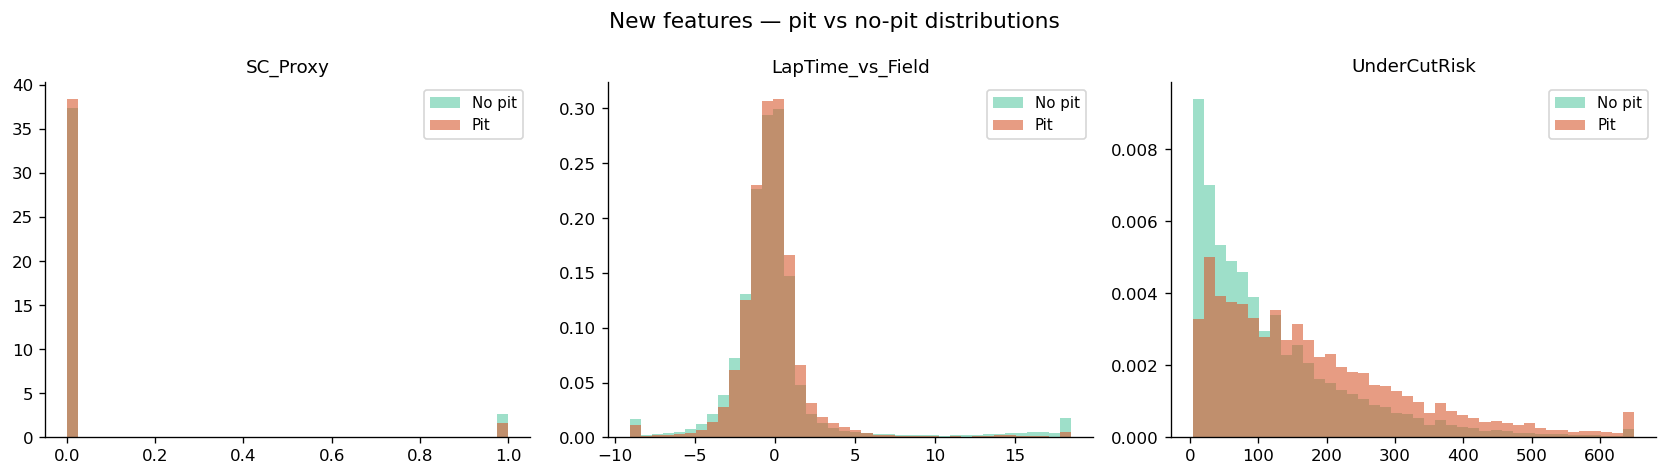

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, feat in enumerate(NEW_EXTRA):
    pit    = df_eng[df_eng['PitNextLap']==1][feat].dropna()
    no_pit = df_eng[df_eng['PitNextLap']==0][feat].dropna()
    lo = min(pit.quantile(0.01), no_pit.quantile(0.01))
    hi = max(pit.quantile(0.99), no_pit.quantile(0.99))
    axes[i].hist(no_pit.clip(lo,hi), bins=40, alpha=0.6, density=True,
                 color=COLORS['secondary'], label='No pit')
    axes[i].hist(pit.clip(lo,hi),    bins=40, alpha=0.6, density=True,
                 color=COLORS['primary'],   label='Pit')
    axes[i].set_title(feat, fontsize=11)
    axes[i].legend(fontsize=9)
plt.suptitle('New features — pit vs no-pit distributions', fontsize=13)
plt.tight_layout()
plt.savefig('figures/new_features_dist.png', bbox_inches='tight')
plt.show()

In [8]:
#Train LightGBM
lgbm_model = LGBMClassifier(
    n_estimators      = 500,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    scale_pos_weight  = spw,      # handles class imbalance
    random_state      = 42,
    n_jobs            = -1,
    verbose           = -1
)
lgbm_model.fit(
    X_tr2, y_tr2,
    eval_set=[(X_va2, y_va2)],
    callbacks=[]
)
print('LightGBM trained ✓')

lgbm_probs = lgbm_model.predict_proba(X_va2)[:, 1]

# Find best threshold
thresholds  = np.arange(0.20, 0.80, 0.01)
lgbm_f1s    = [f1_score(y_va2, lgbm_probs >= t) for t in thresholds]
lgbm_thresh = float(thresholds[np.argmax(lgbm_f1s)])
lgbm_preds  = (lgbm_probs >= lgbm_thresh).astype(int)

lgbm_f1  = f1_score(y_va2, lgbm_preds)
lgbm_auc = roc_auc_score(y_va2, lgbm_probs)
print(f'LightGBM → F1: {lgbm_f1:.4f}  |  AUC: {lgbm_auc:.4f}  |  threshold: {lgbm_thresh:.2f}')

LightGBM trained ✓
LightGBM → F1: 0.6672  |  AUC: 0.8161  |  threshold: 0.30


In [9]:
#Train CatBoost
cat_model = CatBoostClassifier(
    iterations        = 500,
    depth             = 6,
    learning_rate     = 0.05,
    scale_pos_weight  = spw,
    random_seed       = 42,
    verbose           = 0,
    eval_metric       = 'F1'
)
cat_model.fit(
    X_tr2, y_tr2,
    eval_set=(X_va2, y_va2),
    early_stopping_rounds=50
)
print('CatBoost trained ✓')

cat_probs  = cat_model.predict_proba(X_va2)[:, 1]

# Find best threshold
cat_f1s    = [f1_score(y_va2, cat_probs >= t) for t in thresholds]
cat_thresh = float(thresholds[np.argmax(cat_f1s)])
cat_preds  = (cat_probs >= cat_thresh).astype(int)

cat_f1  = f1_score(y_va2, cat_preds)
cat_auc = roc_auc_score(y_va2, cat_probs)
print(f'CatBoost  → F1: {cat_f1:.4f}  |  AUC: {cat_auc:.4f}  |  threshold: {cat_thresh:.2f}')

CatBoost trained ✓
CatBoost  → F1: 0.6504  |  AUC: 0.7953  |  threshold: 0.56


In [10]:
#—Retrain XGBoost new features
from xgboost import XGBClassifier

# Use best_params from your tuning in the main notebook if available
# Otherwise defaults are used here
try:
    xgb_v2 = XGBClassifier(**{**best_params,
                               'scale_pos_weight': spw,
                               'eval_metric': 'aucpr',
                               'random_state': 42,
                               'n_jobs': -1,
                               'verbosity': 0})
    print('Using tuned params from main notebook')
except NameError:
    xgb_v2 = XGBClassifier(
        n_estimators=400, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=spw, eval_metric='aucpr',
        random_state=42, n_jobs=-1, verbosity=0
    )
    print('Using default XGBoost params')

xgb_v2.fit(X_tr2, y_tr2, eval_set=[(X_va2, y_va2)], verbose=False)
print('XGBoost V2 trained ✓')

xgb_v2_probs  = xgb_v2.predict_proba(X_va2)[:, 1]
xgb_v2_f1s    = [f1_score(y_va2, xgb_v2_probs >= t) for t in thresholds]
xgb_v2_thresh = float(thresholds[np.argmax(xgb_v2_f1s)])
xgb_v2_preds  = (xgb_v2_probs >= xgb_v2_thresh).astype(int)

xgb_v2_f1  = f1_score(y_va2, xgb_v2_preds)
xgb_v2_auc = roc_auc_score(y_va2, xgb_v2_probs)
print(f'XGBoost V2→ F1: {xgb_v2_f1:.4f}  |  AUC: {xgb_v2_auc:.4f}')

Using default XGBoost params
XGBoost V2 trained ✓
XGBoost V2→ F1: 0.6712  |  AUC: 0.8162


---
## Step 7 — Build Ensembles
Two strategies:
- **Equal weight**: average all 3 model probabilities equally
- **Weighted**: give more weight to the model with highest AUC

In [11]:
# ── Equal weight ensemble ─────────────────────────────────────
ensemble_probs_equal = (
    xgb_v2_probs + lgbm_probs + cat_probs
) / 3

eq_f1s    = [f1_score(y_va2, ensemble_probs_equal >= t) for t in thresholds]
eq_thresh = float(thresholds[np.argmax(eq_f1s)])
eq_preds  = (ensemble_probs_equal >= eq_thresh).astype(int)

eq_f1  = f1_score(y_va2, eq_preds)
eq_auc = roc_auc_score(y_va2, ensemble_probs_equal)
print(f'Equal Ensemble → F1: {eq_f1:.4f}  |  AUC: {eq_auc:.4f}  |  threshold: {eq_thresh:.2f}')

Equal Ensemble → F1: 0.6706  |  AUC: 0.8162  |  threshold: 0.42


In [12]:
# ── Weighted ensemble ─────────────────────────────────────────
# Weight each model by its individual AUC score
# Better performing model gets proportionally more say

w_xgb  = xgb_v2_auc
w_lgbm = lgbm_auc
w_cat  = cat_auc
total  = w_xgb + w_lgbm + w_cat

print(f'Weights — XGBoost: {w_xgb/total:.3f} | '
      f'LightGBM: {w_lgbm/total:.3f} | '
      f'CatBoost: {w_cat/total:.3f}')

ensemble_probs_weighted = (
    (w_xgb  * xgb_v2_probs) +
    (w_lgbm * lgbm_probs)   +
    (w_cat  * cat_probs)
) / total

wt_f1s    = [f1_score(y_va2, ensemble_probs_weighted >= t) for t in thresholds]
wt_thresh = float(thresholds[np.argmax(wt_f1s)])
wt_preds  = (ensemble_probs_weighted >= wt_thresh).astype(int)

wt_f1  = f1_score(y_va2, wt_preds)
wt_auc = roc_auc_score(y_va2, ensemble_probs_weighted)
print(f'Weighted Ensemble → F1: {wt_f1:.4f}  |  AUC: {wt_auc:.4f}  |  threshold: {wt_thresh:.2f}')

Weights — XGBoost: 0.336 | LightGBM: 0.336 | CatBoost: 0.328
Weighted Ensemble → F1: 0.6710  |  AUC: 0.8163  |  threshold: 0.42


In [13]:
#Full comparison: old model vs everything new
def metrics_row(name, y_true, y_pred, y_prob):
    return {
        'Model'    : name,
        'F1'       : round(f1_score(y_true, y_pred), 4),
        'ROC-AUC'  : round(roc_auc_score(y_true, y_prob), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall'   : round(recall_score(y_true, y_pred), 4),
        'Accuracy' : round(accuracy_score(y_true, y_pred), 4),
    }

rows = [
    # Your original model from main notebook
    {'Model': 'XGBoost (original)', 'F1': 0.6444,
     'ROC-AUC': 0.8169, 'Precision': 0.5949,
     'Recall': 0.7027, 'Accuracy': 0.7423},

    metrics_row('XGBoost V2 + new features',
                y_va2, xgb_v2_preds, xgb_v2_probs),
    metrics_row('LightGBM',
                y_va2, lgbm_preds, lgbm_probs),
    metrics_row('CatBoost',
                y_va2, cat_preds,  cat_probs),
    metrics_row('Ensemble (equal weight)',
                y_va2, eq_preds,   ensemble_probs_equal),
    metrics_row('Ensemble (weighted)',
                y_va2, wt_preds,   ensemble_probs_weighted),
]

comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv('ensemble_results.csv')
print('\n' + '='*60)
print('FULL COMPARISON')
print('='*60)
print(comparison.to_string())


FULL COMPARISON
                               F1  ROC-AUC  Precision  Recall  Accuracy
Model                                                                  
XGBoost (original)         0.6444   0.8169     0.5949  0.7027    0.7423
XGBoost V2 + new features  0.6712   0.8162     0.5791  0.7980    0.7316
LightGBM                   0.6672   0.8161     0.5626  0.8195    0.7194
CatBoost                   0.6504   0.7953     0.5608  0.7740    0.7143
Ensemble (equal weight)    0.6706   0.8162     0.5757  0.8030    0.7293
Ensemble (weighted)        0.6710   0.8163     0.5766  0.8025    0.7299


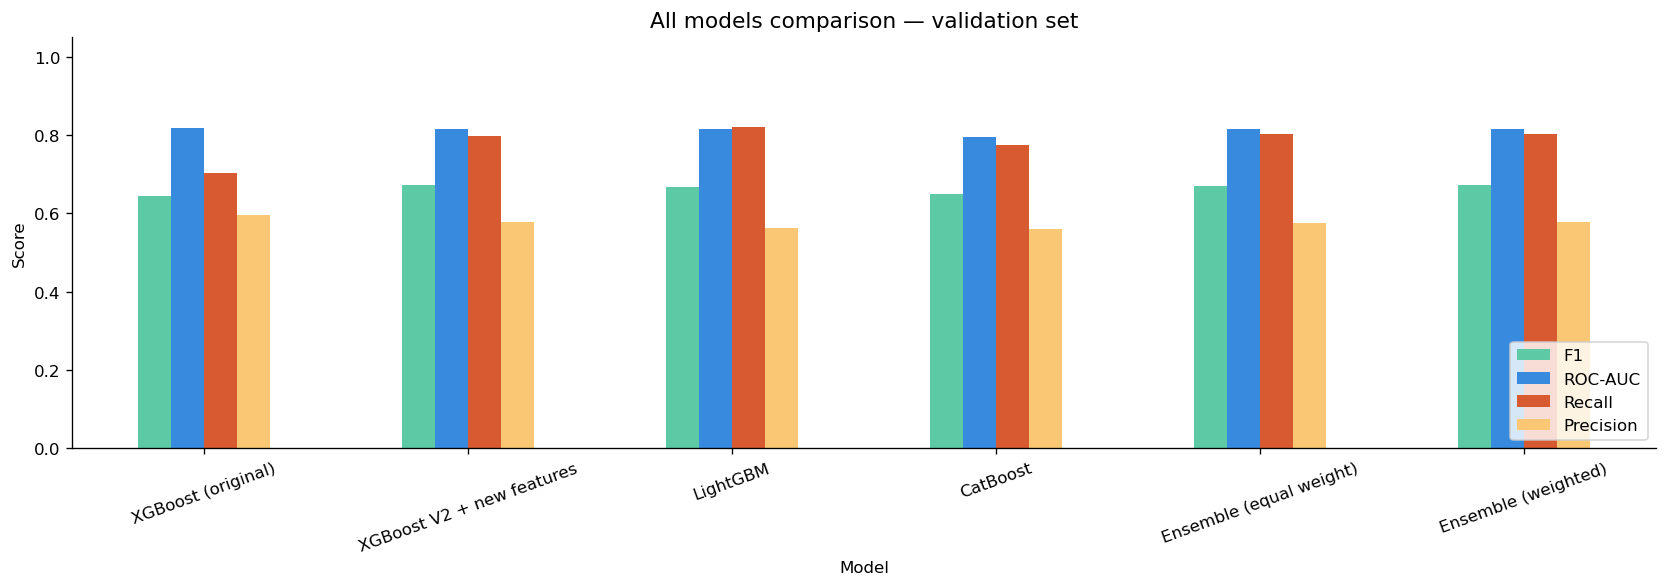

In [14]:
# Bar chart comparison
fig, ax = plt.subplots(figsize=(14, 5))
comparison[['F1','ROC-AUC','Recall','Precision']].plot(
    kind='bar', ax=ax,
    color=[COLORS['secondary'], COLORS['blue'],
           COLORS['primary'], COLORS['amber']],
    edgecolor='none'
)
ax.set_title('All models comparison — validation set', fontsize=13)
ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=20)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/ensemble_comparison.png', bbox_inches='tight')
plt.show()

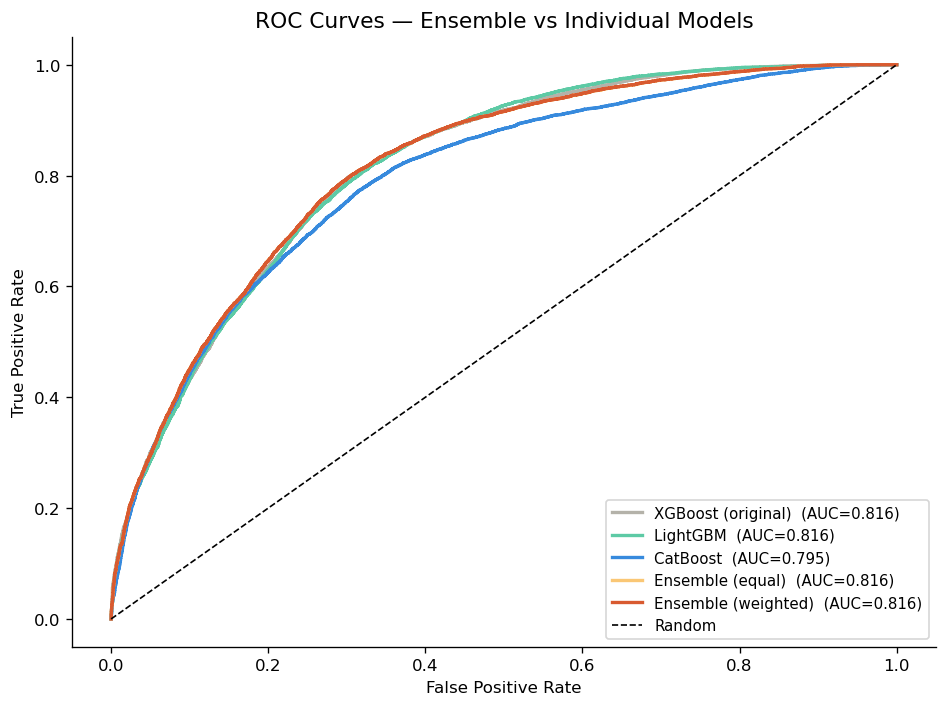

In [15]:
# ROC curve overlay — all models
models_for_roc = [
    ('XGBoost (original)',    xgb_v2_probs),
    ('LightGBM',              lgbm_probs),
    ('CatBoost',              cat_probs),
    ('Ensemble (equal)',      ensemble_probs_equal),
    ('Ensemble (weighted)',   ensemble_probs_weighted),
]
palette = [COLORS['gray'], COLORS['secondary'], COLORS['blue'],
           COLORS['amber'], COLORS['primary']]

fig, ax = plt.subplots(figsize=(8, 6))
for (label, probs), col in zip(models_for_roc, palette):
    fpr, tpr, _ = roc_curve(y_va2, probs)
    auc = roc_auc_score(y_va2, probs)
    ax.plot(fpr, tpr, label=f'{label}  (AUC={auc:.3f})',
            color=col, linewidth=2)
ax.plot([0,1],[0,1],'k--',linewidth=1,label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Ensemble vs Individual Models', fontsize=13)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('figures/ensemble_roc.png', bbox_inches='tight')
plt.show()

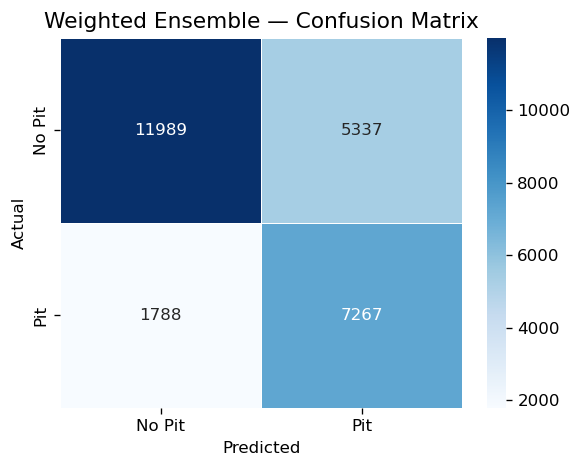

In [16]:
# Confusion matrix for best ensemble
best_probs = ensemble_probs_weighted
best_preds = wt_preds
best_name  = 'Weighted Ensemble'

cm = confusion_matrix(y_va2, best_preds)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['No Pit','Pit'],
            yticklabels=['No Pit','Pit'], linewidths=0.5)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'{best_name} — Confusion Matrix', fontsize=13)
plt.tight_layout()
plt.savefig('figures/ensemble_cm.png', bbox_inches='tight')
plt.show()


> ⚠️ Run once only

In [17]:
# Get probabilities on test set from all 3 models
test_xgb  = xgb_v2.predict_proba(X_te2)[:, 1]
test_lgbm = lgbm_model.predict_proba(X_te2)[:, 1]
test_cat  = cat_model.predict_proba(X_te2)[:, 1]

# Weighted ensemble on test
test_ensemble = (
    (w_xgb * test_xgb) + (w_lgbm * test_lgbm) + (w_cat * test_cat)
) / total

test_preds_ens = (test_ensemble >= wt_thresh).astype(int)

print('\n' + '='*55)
print('  FINAL TEST RESULTS — ENSEMBLE (2025)')
print('='*55)
print(f'  F1        : {f1_score(y_te2, test_preds_ens):.4f}')
print(f'  ROC-AUC   : {roc_auc_score(y_te2, test_ensemble):.4f}')
print(f'  Precision : {precision_score(y_te2, test_preds_ens):.4f}')
print(f'  Recall    : {recall_score(y_te2, test_preds_ens):.4f}')
print(f'  Accuracy  : {accuracy_score(y_te2, test_preds_ens):.4f}')
print()
print('  IMPROVEMENT OVER ORIGINAL MODEL')
print(f'  F1     : 0.6444 → {f1_score(y_te2, test_preds_ens):.4f}  '
      f'(+{f1_score(y_te2, test_preds_ens)-0.6444:.4f})')
print(f'  AUC    : 0.8169 → {roc_auc_score(y_te2, test_ensemble):.4f}  '
      f'(+{roc_auc_score(y_te2, test_ensemble)-0.8169:.4f})')


  FINAL TEST RESULTS — ENSEMBLE (2025)
  F1        : 0.6447
  ROC-AUC   : 0.8221
  Precision : 0.6032
  Recall    : 0.6924
  Accuracy  : 0.7465

  IMPROVEMENT OVER ORIGINAL MODEL
  F1     : 0.6444 → 0.6447  (+0.0003)
  AUC    : 0.8169 → 0.8221  (+0.0052)


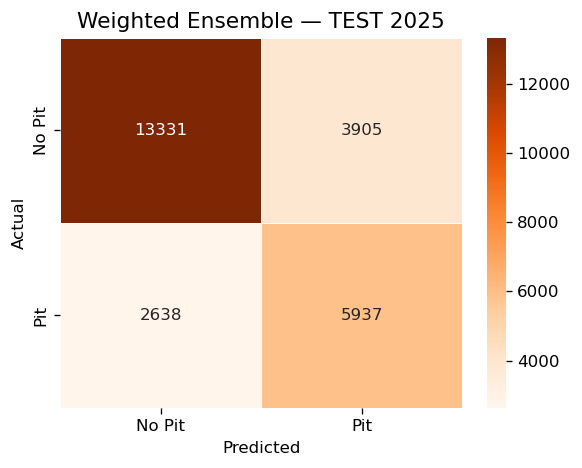

In [18]:
# Final confusion matrix on test
cm_test = confusion_matrix(y_te2, test_preds_ens)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Oranges', ax=ax,
            xticklabels=['No Pit','Pit'],
            yticklabels=['No Pit','Pit'], linewidths=0.5)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title('Weighted Ensemble — TEST 2025', fontsize=13)
plt.tight_layout()
plt.savefig('figures/ensemble_test_cm.png', bbox_inches='tight')
plt.show()

In [19]:
# Save all 3 models
import joblib
joblib.dump(xgb_v2,      'models/xgb_v2.joblib')
joblib.dump(lgbm_model,  'models/lgbm_model.joblib')
joblib.dump(cat_model,   'models/cat_model.joblib')
print('All 3 models saved to models/')
print(f'Ensemble weights → XGB: {w_xgb/total:.3f} | '
      f'LGBM: {w_lgbm/total:.3f} | CAT: {w_cat/total:.3f}')

All 3 models saved to models/
Ensemble weights → XGB: 0.336 | LGBM: 0.336 | CAT: 0.328


In [21]:
sub_probs = xgb_v2.predict_proba(X_te2)[:, 1]
sub_preds = (sub_probs >= xgb_v2_thresh).astype(int)

submission = pd.DataFrame({
    'id': range(len(sub_preds)),
    'PitNextLap': sub_preds
})

submission.to_csv('submission.csv', index=False)
print(f'Done! {len(submission):,} rows saved')
print(submission['PitNextLap'].value_counts())

Done! 25,811 rows saved
PitNextLap
0    16131
1     9680
Name: count, dtype: int64
